# 07-1. 단기 메모리: Checkpoint로 대화 이어가기
## 학습 목표
- `ChatState`와 `InMemorySaver`로 한 대화 스레드의 메시지를 유지한다.
- 같은 `thread_id`와 다른 `thread_id`의 State를 비교한다.
- State, 대화 기록, Checkpoint의 관계를 설명한다.

**준비:** OpenAI API 키가 필요하다. 기본 모델 `gpt-4o-mini`를 세 번 호출한다.

## 핵심 개념과 실행 전 예측
단기 메모리는 현재 대화 스레드의 State를 다음 호출에 이어 쓰는 방식이다.  
`ChatState`의 `messages`는 대화 기록이고, Checkpointer는 Graph State의 스냅샷을 `thread_id`별로 저장한다.  
같은 ID로 두 번째 질문을 하면 메시지가 몇 개가 될까? 다른 ID는 앞 대화를 볼 수 있을까?

이 실습의 `InMemorySaver`는 Python 프로세스의 메모리에만 기록한다. 재시작 뒤에도 남는 저장소는 아니다.

## 기본 설정

In [1]:
from langchain_core.globals import set_llm_cache, get_llm_cache
from langchain_core.caches import InMemoryCache
from common.ai_model import get_llm_model

# 동일한 프롬프트+모델 파라미터로 호출하면 API를 다시 부르지 않고
# 캐시된 응답을 즉시 반환한다. 커널을 재시작하면 캐시는 사라진다.
set_llm_cache(InMemoryCache())

llm_options = {"model": "gpt-4o-mini", "temperature": 0}

llm = get_llm_model(**llm_options)
print("사용 모델:", llm_options["model"])
print("캐시 종류:", type(get_llm_cache()).__name__)

사용 모델: gpt-4o-mini
캐시 종류: InMemoryCache


## 그래프 설계

In [2]:
from typing import Annotated
from pydantic import BaseModel
from langchain_core.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import START, END, StateGraph
from langgraph.graph.message import add_messages

# MessagesState(TypedDict) 대신 Pydantic으로 동일한 역할의 State를 정의한다.
class ChatState(BaseModel):
    messages: Annotated[list, add_messages]

def chat_node(state: ChatState) -> dict:
    # 이미 저장된 메시지와 새 질문을 함께 모델에 전달한다.
    response = llm.invoke(state.messages)
    return {"messages": [response]}

builder = StateGraph(ChatState)
builder.add_node("chat", chat_node)
builder.add_edge(START, "chat")
builder.add_edge("chat", END)


# InMemorySaver를 사용하여 체크포인트를 저장한다. 체크포인트를 사용하면 이전 상태로 돌아가거나, 여러 시나리오를 테스트할 수 있다.
checkpointer = InMemorySaver()

# StateGraph를 컴파일하고
graph = builder.compile(checkpointer=checkpointer)

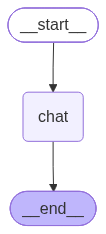

In [3]:
from common.utils import visualize_graph
visualize_graph(graph)

### 대화 단기 기억을 위한 스레드 정의

In [4]:
# the InMemorySaver를 사용하면 여러 시나리오를 테스트할 수 있다. 예를 들어, Alice와 Bob이 각각 다른 대화 스레드를 갖도록 설정할 수 있다.
# alice/bob 딕셔너리는 checkpointer가 어떤 저장소를 찾을지 알려주는 키임.
alice = {"configurable": {"thread_id": "learner-alice"}}
bob = {"configurable": {"thread_id": "learner-bob"}}

In [5]:
# Alice와의 첫 대화, 이때 Alice의 thread_id를 사용하여 대화 상태를 저장한다.
first = graph.invoke({"messages": [HumanMessage(content="내 이름은 민지야. 이름만 기억해줘.")]}, config=alice)
print("첫 대화의 마지막 답:", first["messages"][-1].content)
print("첫 대화 메시지 수:", len(first["messages"]))

첫 대화의 마지막 답: 알겠어요, 민지라고 기억할게요.
첫 대화 메시지 수: 2


In [6]:
first

{'messages': [HumanMessage(content='내 이름은 민지야. 이름만 기억해줘.', additional_kwargs={}, response_metadata={}, id='3a0c2ff3-8c72-4093-8a90-d2b9d24f0fad'),
  AIMessage(content='알겠어요, 민지라고 기억할게요.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 19, 'total_tokens': 34, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.4-mini', 'system_fingerprint': None, 'id': 'chatcmpl-EYjQzpK53lkqjdGnKHwyYbdGjVMLk', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a13855-ce1d-7f50-bbf7-e4933bfefcee-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 19, 'output_tokens': 15, 'total_tokens': 34, 'in

In [7]:
# Alice와의 두 번째 대화, 이전 대화 상태를 불러와서 이어서 진행한다. thread_id가 같으므로 이전 메시지들이 그대로 유지된다.
second = graph.invoke({"messages": [HumanMessage(content="내 이름이 뭐였지? 한 단어로 답해줘.")]}, config=alice)
print("같은 thread_id의 답:", second["messages"][-1].content)
print("같은 thread_id 메시지 수:", len(second["messages"]))
assert len(second["messages"]) == 4

같은 thread_id의 답: 민지
같은 thread_id 메시지 수: 4


In [8]:
second

{'messages': [HumanMessage(content='내 이름은 민지야. 이름만 기억해줘.', additional_kwargs={}, response_metadata={}, id='3a0c2ff3-8c72-4093-8a90-d2b9d24f0fad'),
  AIMessage(content='알겠어요, 민지라고 기억할게요.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 19, 'total_tokens': 34, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.4-mini', 'system_fingerprint': None, 'id': 'chatcmpl-EYjQzpK53lkqjdGnKHwyYbdGjVMLk', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a13855-ce1d-7f50-bbf7-e4933bfefcee-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 19, 'output_tokens': 15, 'total_tokens': 34, 'in

In [9]:
other = graph.invoke({"messages": [HumanMessage(content="내 이름이 뭐였지? 모르면 모른다고 답해줘.")]}, config=bob)
print("다른 thread_id의 답:", other["messages"][-1].content)
print("다른 thread_id 메시지 수:", len(other["messages"]))
assert len(other["messages"]) == 2

다른 thread_id의 답: 모르겠습니다.
다른 thread_id 메시지 수: 2


In [10]:
saved_alice = graph.get_state(alice)
saved_bob = graph.get_state(bob)
print("저장된 State의 메시지 수:", len(saved_alice.values["messages"]), len(saved_bob.values["messages"]))
print("Alice 다음 실행 위치:", saved_alice.next)
assert len(saved_alice.values["messages"]) == 4

저장된 State의 메시지 수: 4 2
Alice 다음 실행 위치: ()


### ① Checkpointer의 저장·복원 구조와 ② Alice/Bob 스레드별 메모리 분리 흐름

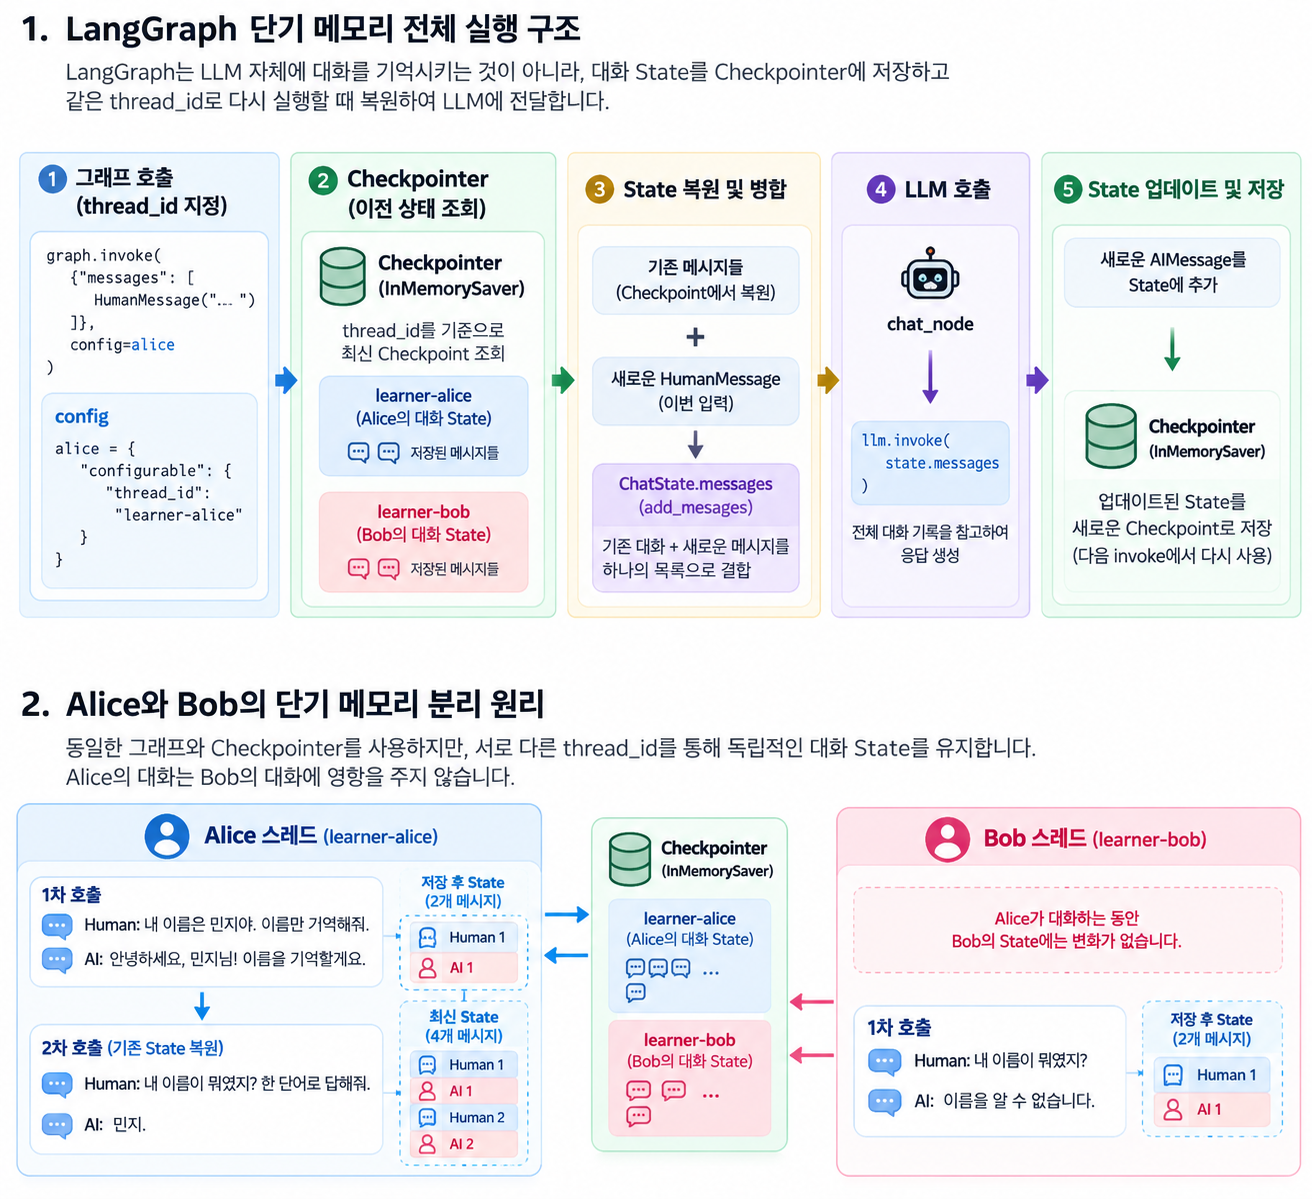

## State 변화 관찰
첫 번째 호출 후 Alice의 메시지는 사용자·AI 2개, 두 번째 호출 후에는 4개이다. Bob은 별도 `thread_id`에서 시작해 2개이다. 자연어 답변의 표현보다 이 수치와 `get_state()` 결과를 확인한다. `get_state()`의 `values`는 저장된 State이고, `next`가 비어 있으면 현재 실행이 끝난 상태이다.

**장기 메모리와의 차이:** 여기서 저장한 Alice의 대화 기록은 Bob의 스레드로 자동 공유되지 않는다. 다음 07-2에서는 Store를 사용해 스레드를 넘어 필요한 정보를 직접 저장·검색한다.

## 이해 확인
1. 같은 Graph인데 `thread_id`가 다르면 대화 기록이 갈라지는 이유는 무엇인가?  
   **해설:** Checkpointer가 `thread_id`별 State 스냅샷을 구분해 저장하기 때문이다.
2. `InMemorySaver`에 저장한 기록은 Python 재시작 뒤에도 남는가?  
   **해설:** 아니다. 교육용 메모리 저장소라 프로세스 종료 시 사라진다.

**핵심 정리:** 단기 메모리는 현재 스레드의 대화 State를 이어 주며, `thread_id`가 어느 대화를 재개할지 지정한다.